In [107]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# 1. Buat dataset dummy
data = {
    'player_name': ['Andi', 'Budi', 'Cahyo', 'Dedi', 'Eko', 'Fajar', 'Gilang', 'Hendra', 'Indra', 'Joko', 
                    'Kurniawan', 'Lutfi', 'Mulyadi', 'Nugroho', 'Oki', 'Pandu', 'Rahmat', 'Samsul', 'Taufik', 'Umar'],
    'position': ['Forward', 'Midfielder', 'Defender', 'Midfielder', 'Forward', 'Goalkeeper', 'Forward', 
                 'Defender', 'Goalkeeper', 'Midfielder', 'Defender', 'Forward', 'Defender', 'Midfielder', 
                 'Forward', 'Goalkeeper', 'Defender', 'Forward', 'Midfielder', 'Defender'],
    'goals_scored': [5, 2, 0, 3, 7, 0, 6, 1, 0, 2, 0, 4, 1, 0, 5, 0, 0, 3, 1, 0],
    'assists': [3, 1, 2, 0, 5, 0, 3, 2, 0, 4, 0, 2, 1, 1, 3, 0, 2, 2, 3, 1],
    'passes_completed': [100, 80, 90, 70, 110, 50, 95, 75, 40, 85, 60, 95, 80, 65, 105, 55, 70, 80, 60, 50],
    'tackles': [10, 8, 5, 7, 12, 1, 9, 6, 2, 10, 5, 4, 6, 7, 8, 3, 5, 9, 4, 5],
    'saving': [0, 0, 0, 0, 0, 10, 0, 0, 15, 0, 0, 0, 0, 0, 0, 6, 0, 0, 0, 0]
}

df = pd.DataFrame(data)

# 2. Tambahkan kolom total_statistics sebagai target
df['total_statistics'] = (df['goals_scored'] + 
                          df['assists'] + 
                          df['passes_completed']*0.01 +  # Normalisasi nilai yang lebih besar
                          df['tackles']*0.1 +            # Berikan bobot pada tackles
                          df['saving']*0.1)    # Normalisasi nilai yang lebih besar

# Encode posisi menjadi numerik
df['position_encoded'] = df['position'].map({
    'Forward': 0,
    'Midfielder': 1,
    'Defender': 2,
    'Goalkeeper': 3
})

df


,player_name,position,goals_scored,assists,passes_completed,tackles,saving,total_statistics,position_encoded
0,Andi,Forward,5,3,100,10,0,10.00,0
1,Budi,Midfielder,2,1,80,8,0,4.60,1
2,Cahyo,Defender,0,2,90,5,0,3.40,2
3,Dedi,Midfielder,3,0,70,7,0,4.40,1
4,Eko,Forward,7,5,110,12,0,14.30,0
5,Fajar,Goalkeeper,0,0,50,1,10,1.60,3
6,Gilang,Forward,6,3,95,9,0,10.85,0
7,Hendra,Defender,1,2,75,6,0,4.35,2
8,Indra,Goalkeeper,0,0,40,2,15,2.10,3
9,Joko,Midfielder,2,4,85,10,0,7.85,1


In [108]:
X = df[['goals_scored', 'assists', 'passes_completed', 'tackles', 'saving', 'position_encoded']]
y = df['total_statistics']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

regressor = RandomForestRegressor(random_state=42)
regressor.fit(X_train, y_train)

y_pred = regressor.predict(X_test)
df['predicted_total_statistics'] = regressor.predict(X)

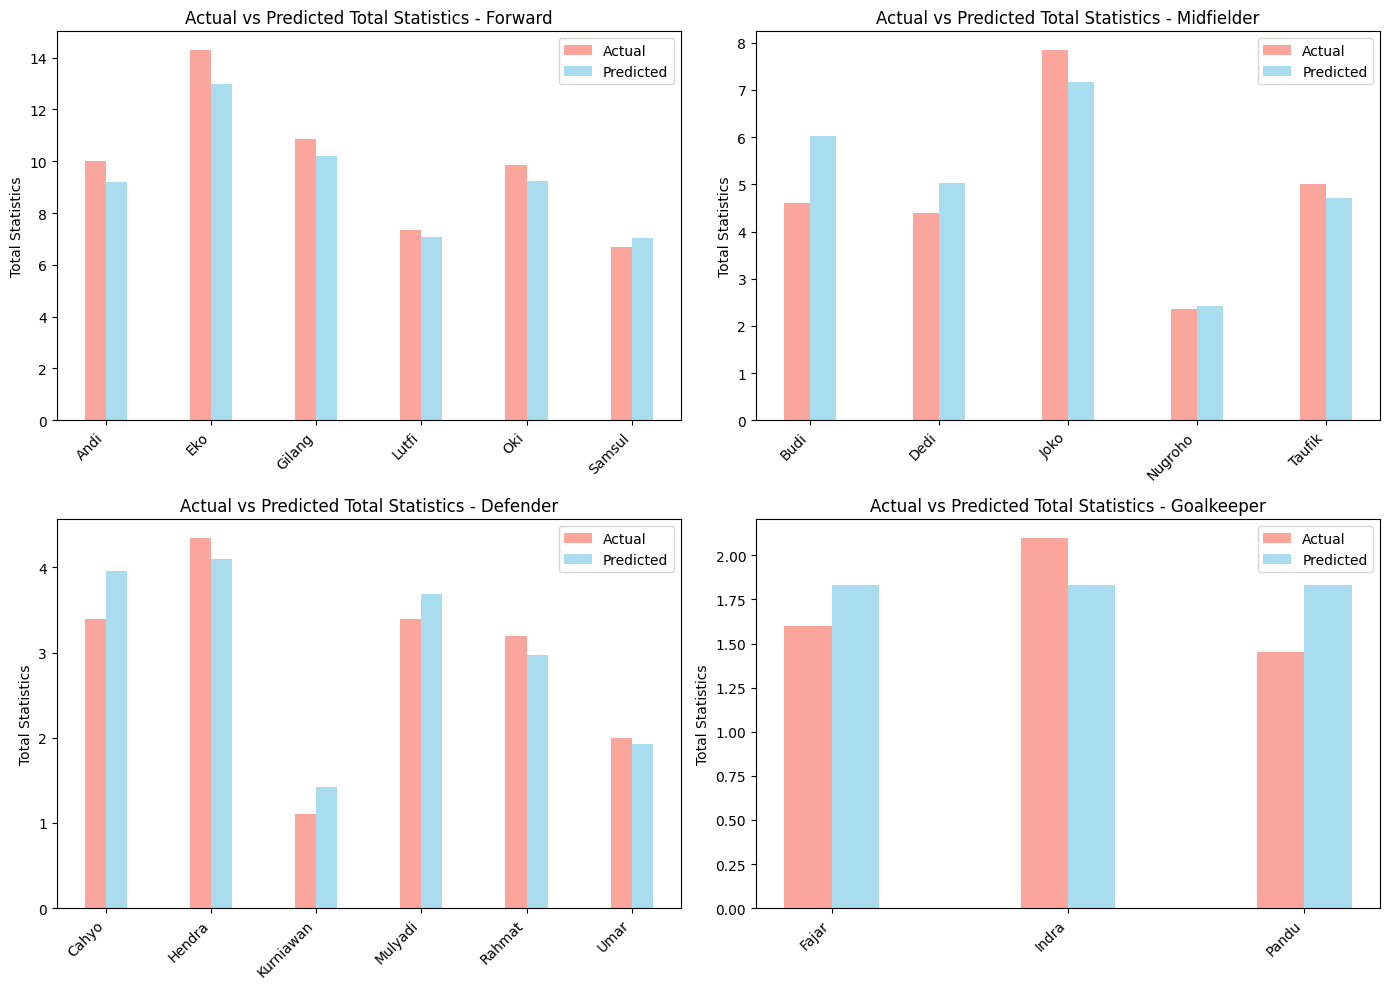

In [110]:
# Create a figure for the bar plots
unique_positions = df['position_encoded'].unique()
position_names = {0: 'Forward', 1: 'Midfielder', 2: 'Defender', 3: 'Goalkeeper'}

plt.figure(figsize=(14, 10))

bar_width = 0.2 

for i, position in enumerate(unique_positions):
    # Filter data for the current position
    position_df = df[df['position_encoded'] == position]
    
    # Create an index for each player's bars
    index = np.arange(len(position_df['player_name']))
    
    # Create bar plot
    plt.subplot(2, 2, i + 1)
    plt.bar(index, position_df['total_statistics'], width=bar_width, label='Actual', color='salmon', alpha=0.7)
    plt.bar(index + bar_width, position_df['predicted_total_statistics'], width=bar_width, label='Predicted', color='skyblue', alpha=0.7)

    # Labeling
    plt.title(f'Actual vs Predicted Total Statistics - {position_names[position]}')
    plt.ylabel('Total Statistics')
    plt.xticks(index + bar_width / 2, position_df['player_name'], rotation=45, ha='right')
    plt.legend()

plt.tight_layout()
plt.show()

In [111]:
# 6

r2 = r2_score(y_test, y_pred)
print("R-squared (R²) Score:", r2)

R-squared (R²) Score: 0.9480773910133642


In [112]:
# 7. Rekomendasikan formasi

def recommend_formation(df, n_defenders=4, n_midfielders=3, n_forwards=3):
    forwards = df[df['position'] == 'Forward'].sort_values(by='predicted_total_statistics', ascending=False).head(n_forwards)
    midfielders = df[df['position'] == 'Midfielder'].sort_values(by='predicted_total_statistics', ascending=False).head(n_midfielders)
    defenders = df[df['position'] == 'Defender'].sort_values(by='predicted_total_statistics', ascending=False).head(n_defenders)
    goalkeeper = df[df['position'] == 'Goalkeeper'].sort_values(by='predicted_total_statistics', ascending=False).head(1)
    
    team = pd.concat([goalkeeper, defenders, midfielders, forwards])
    return team

# Tentukan formasi 4-3-3
model_team = recommend_formation(df)

model_team[["player_name", "position"]]

,player_name,position
5,Fajar,Goalkeeper
7,Hendra,Defender
2,Cahyo,Defender
12,Mulyadi,Defender
16,Rahmat,Defender
9,Joko,Midfielder
1,Budi,Midfielder
3,Dedi,Midfielder
4,Eko,Forward
6,Gilang,Forward


In [113]:
# 8. Buat data baru sebanyak 20 pemain, sertakan nama pemain

data_baru = {
    'player_name': ['Andi', 'Budi', 'Cahyo', 'Dedi', 'Eko', 'Fajar', 'Gilang', 'Hendra', 'Indra', 'Joko', 
                    'Kurniawan', 'Lutfi', 'Mulyadi', 'Nugroho', 'Oki', 'Pandu', 'Rahmat', 'Samsul', 'Taufik', 'Umar'],
    'position': ['Forward', 'Midfielder', 'Defender', 'Midfielder', 'Forward', 'Goalkeeper', 'Forward', 
                 'Defender', 'Goalkeeper', 'Midfielder', 'Defender', 'Forward', 'Defender', 'Midfielder', 
                 'Forward', 'Goalkeeper', 'Defender', 'Forward', 'Midfielder', 'Defender'],
    'goals_scored': [3, 4, 1, 0, 6, 0, 4, 2, 1, 3, 5, 0, 2, 4, 1, 0, 5, 0, 3, 2],
    'assists': [2, 3, 1, 0, 5, 0, 3, 2, 1, 2, 4, 0, 1, 3, 2, 1, 4, 0, 2, 1],
    'passes_completed': [90, 110, 80, 70, 120, 50, 95, 80, 60, 85, 110, 40, 75, 95, 85, 65, 100, 50, 90, 80],
    'tackles': [8, 9, 4, 3, 12, 1, 7, 5, 3, 7, 11, 2, 6, 9, 5, 4, 10, 2, 8, 6],
    'saving': [0, 0, 0, 0, 0, 8, 0, 0, 12, 0, 0, 0, 0, 0, 0, 10, 0, 0, 0, 0],
}

# Encode posisi menjadi numerik
data_baru['position_encoded'] = df['position'].map({
    'Forward': 0,
    'Midfielder': 1,
    'Defender': 2,
    'Goalkeeper': 3
})

# Buat DataFrame baru
df_baru = pd.DataFrame(data_baru)
df_baru

,player_name,position,goals_scored,assists,passes_completed,tackles,saving,position_encoded
0,Andi,Forward,3,2,90,8,0,0
1,Budi,Midfielder,4,3,110,9,0,1
2,Cahyo,Defender,1,1,80,4,0,2
3,Dedi,Midfielder,0,0,70,3,0,1
4,Eko,Forward,6,5,120,12,0,0
5,Fajar,Goalkeeper,0,0,50,1,8,3
6,Gilang,Forward,4,3,95,7,0,0
7,Hendra,Defender,2,2,80,5,0,2
8,Indra,Goalkeeper,1,1,60,3,12,3
9,Joko,Midfielder,3,2,85,7,0,1


In [114]:
# 9. Prediksi nilai total statistik baru
prediksi_baru = regressor.predict(df_baru[['goals_scored', 'assists', 'passes_completed', 'tackles', 'saving', 'position_encoded']])

# 10. Tampilkan hasil prediksi beserta nama pemain
df_baru['predicted_total_statistics'] = prediksi_baru 
df_baru

,player_name,position,goals_scored,assists,passes_completed,tackles,saving,position_encoded,predicted_total_statistics
0,Andi,Forward,3,2,90,8,0,0,7.3325
1,Budi,Midfielder,4,3,110,9,0,1,9.1345
2,Cahyo,Defender,1,1,80,4,0,2,3.9835
3,Dedi,Midfielder,0,0,70,3,0,1,2.6945
4,Eko,Forward,6,5,120,12,0,0,12.1245
5,Fajar,Goalkeeper,0,0,50,1,8,3,1.8300
6,Gilang,Forward,4,3,95,7,0,0,7.3145
7,Hendra,Defender,2,2,80,5,0,2,4.8590
8,Indra,Goalkeeper,1,1,60,3,12,3,3.5410
9,Joko,Midfielder,3,2,85,7,0,1,5.7600


In [115]:
# Tentukan formasi 4-3-3
predict_team = recommend_formation(df_baru)

predict_team[["player_name", "position"]]

,player_name,position
8,Indra,Goalkeeper
10,Kurniawan,Defender
16,Rahmat,Defender
7,Hendra,Defender
12,Mulyadi,Defender
1,Budi,Midfielder
13,Nugroho,Midfielder
18,Taufik,Midfielder
4,Eko,Forward
0,Andi,Forward
